In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('car_price_data.csv')
df.head()

,brand,model,year,km_driven,fuel_type,transmission,owner_type,engine_cc,power_bhp,mileage_kmpl,seats,price_lakh
0,Kia,Seltos,2024,27702,Petrol,Automatic,Second,1497,113.0,15.6,5,9.08
1,Tata,Nexon,2025,11264,Diesel,Manual,First,1199,116.9,17.4,5,8.76
2,Toyota,Glanza,2017,117275,CNG,Automatic,First,1197,82.3,21.3,5,1.59
3,Mahindra,XUV700,2023,29857,Petrol,Automatic,First,1999,196.8,13.6,7,11.85
4,Hyundai,Creta,2018,95565,Diesel,Automatic,First,1493,114.0,16.1,5,3.77


In [3]:
df.isnull().sum()

brand           0
model           0
year            0
km_driven       0
fuel_type       0
transmission    0
owner_type      0
engine_cc       0
power_bhp       0
mileage_kmpl    0
seats           0
price_lakh      0
dtype: int64

In [ ]:
df['Car_age']=2026-df['year']
df=df.drop('year',axis=1)


KeyError: 'year'

In [8]:
df.head(5)

,brand,model,km_driven,fuel_type,transmission,owner_type,engine_cc,power_bhp,mileage_kmpl,seats,price_lakh,Car_age
0,Kia,Seltos,27702,Petrol,Automatic,Second,1497,113.0,15.6,5,9.08,2
1,Tata,Nexon,11264,Diesel,Manual,First,1199,116.9,17.4,5,8.76,1
2,Toyota,Glanza,117275,CNG,Automatic,First,1197,82.3,21.3,5,1.59,9
3,Mahindra,XUV700,29857,Petrol,Automatic,First,1999,196.8,13.6,7,11.85,3
4,Hyundai,Creta,95565,Diesel,Automatic,First,1493,114.0,16.1,5,3.77,8


### Data visualization

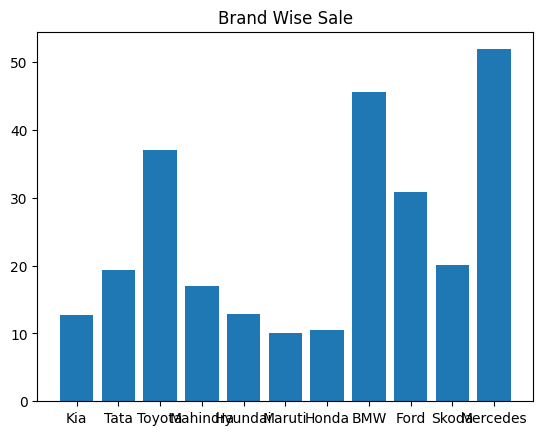

In [4]:
plt.bar(df['brand'],df['price_lakh'])
plt.title('Brand Wise Sale')
plt.show()

In [9]:
df=pd.get_dummies(df,columns=['brand','model','fuel_type','transmission','owner_type'],drop_first=True,dtype=int)



In [10]:
df.head()

,km_driven,engine_cc,power_bhp,mileage_kmpl,seats,price_lakh,Car_age,brand_Ford,brand_Honda,brand_Hyundai,...,model_XUV700,model_i10,model_i20,fuel_type_Diesel,fuel_type_Electric,fuel_type_Petrol,transmission_Manual,owner_type_Fourth & Above,owner_type_Second,owner_type_Third
0,27702,1497,113.0,15.6,5,9.08,2,0,0,0,...,0,0,0,0,0,1,0,0,1,0
1,11264,1199,116.9,17.4,5,8.76,1,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,117275,1197,82.3,21.3,5,1.59,9,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,29857,1999,196.8,13.6,7,11.85,3,0,0,0,...,1,0,0,0,0,1,0,0,0,0
4,95565,1493,114.0,16.1,5,3.77,8,0,0,1,...,0,0,0,1,0,0,0,0,0,0


In [11]:
X=df.drop('price_lakh',axis=1)
y=df['price_lakh']


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)
poly_cols=['Car_age','km_driven','engine_cc','power_bhp']


from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=2,include_bias=False)

train_poly=pd.DataFrame(poly.fit_transform(X_train[poly_cols]),columns=poly.get_feature_names_out(poly_cols),index=X_train.index)
test_poly=pd.DataFrame(poly.transform(X_test[poly_cols]),columns=poly.get_feature_names_out(poly_cols),index=X_test.index)

x_train2=pd.concat([X_train.drop(columns=poly_cols),train_poly],axis=1)
x_test2=pd.concat([X_test.drop(columns=poly_cols),test_poly],axis=1)

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaler=scaler.fit_transform(x_train2)
x_test_scaler=scaler.transform(x_test2)

from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train_scaler,y_train)
predict=model.predict(x_test_scaler)
predict

from sklearn.metrics import r2_score
r2=r2_score(y_test,predict)
r2


0.92048978235606

In [27]:
import joblib
joblib.dump(model,'car_model.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(X.columns.to_list(),'columns.pkl')


['columns.pkl']